# 8. Optimization: Exercise

Name: Xiuning

Date: Nov 25, 2026

## 1. Try with you own function
1) Define a function of your interest (with two or more inputs) to be minimized or maximized.  
It can be an explicit mathematical form, or given implictly as a result of simulation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
# This is just an example. Please define your own function.
def fun(x, a=1.):
    """sine in quardatic valley"""
    x = np.array(x)
    y = (x[0]**2+x[1]**2) + a*np.sin(x[0])
    return y

In [114]:
# Himmelblau function: one local maximum and four identical local minima
def himmelblau(x):
    x = np.array(x)
    y = (x[0]**2 + x[1]**2 - 11)**2 + (x[0] + x[1]**2 - 7)**2
    return y

# Rosenbrock function: its global minimum lies inside a narrow, curved, parabolic valley
def rosenbrock(x, a=1., b=100.):
    x = np.array(x)
    y = (a - x[0])**2 + b*(x[1] - x[0]**2)**2
    return y

def Beale(x):
    x = np.array(x)
    y = (1.5 - x[0] + x[0]*x[1])**2 + (2.25 - x[0] + x[0]*x[1]**2)**2 + (2.625 - x[0] + x[0]*x[1]**3)**2
    return y

2) Visualize the function, e.g., by surface plot or contour plot.

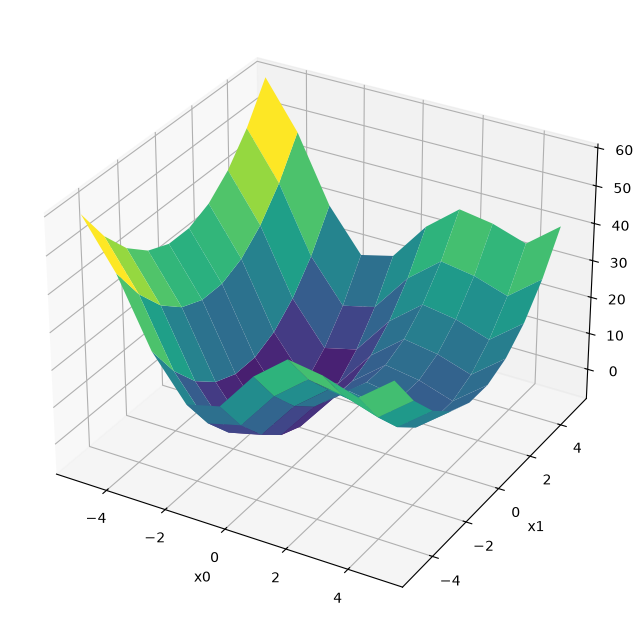

In [ ]:
w = 5
N = 10
x = np.linspace(-w,w,N)
x0, x1 = np.meshgrid(x, x)
#x2 = np.array(x2).transpose(2,1,0)  # (x0,x1) in last dimention
y = fun((x0, x1), 10)
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(projection='3d')
ax.plot_surface(x0, x1, y, cmap='viridis')
plt.xlabel("x0"); plt.ylabel("x1");

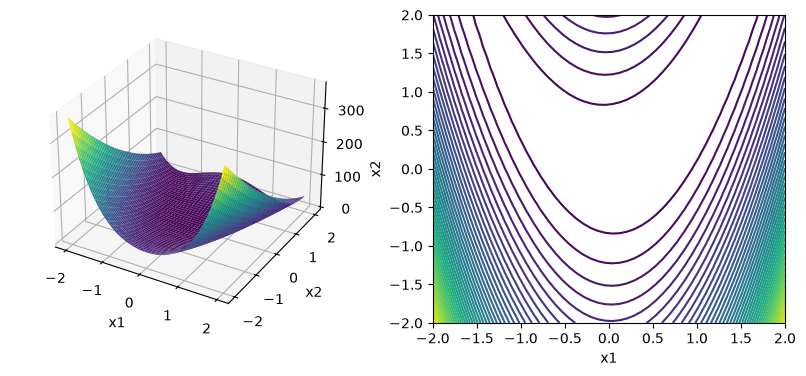

In [ ]:
w = 2
N = 50
x = np.linspace(-w,w,N)
x1, x2 = np.meshgrid(x, x)
#x2 = np.array(x2).transpose(2,1,0)  # (x0,x1) in last dimention
y = rosenbrock((x1, x2), a=1, b=10)
# two subplots, unpack the axes array immediately
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = fig.add_subplot(1, 2, 1, projection='3d')
ax.plot_surface(x1, x2, y, cmap='viridis')
axes[0].axis('off')
axes[1].contour(x1, x2, y, levels=50, cmap='viridis')
ax.set_xlabel("x1"); ax.set_ylabel("x2"); 
axes[1].set_xlabel("x1"); axes[1].set_ylabel("x2");    

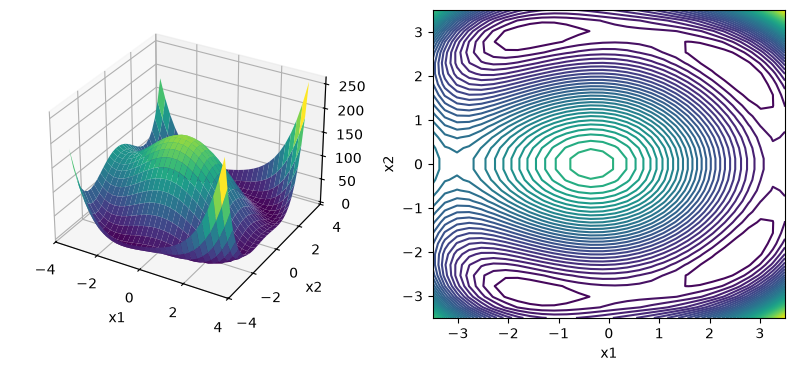

In [128]:
w = 3.5
N = 30
x = np.linspace(-w,w,N)
x1, x2 = np.meshgrid(x, x)
#x2 = np.array(x2).transpose(2,1,0)  # (x0,x1) in last dimention
y = himmelblau((x1, x2))
# two subplots, unpack the axes array immediately
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = fig.add_subplot(1, 2, 1, projection='3d')
ax.plot_surface(x1, x2, y, cmap='viridis')
axes[0].axis('off')
axes[1].contour(x1, x2, y, levels=50, cmap='viridis')
ax.set_xlabel("x1"); ax.set_ylabel("x2");    
axes[1].set_xlabel("x1"); axes[1].set_ylabel("x2");    

Locator attempting to generate 6947 ticks ([0.0, ..., 10419.0]), which exceeds Locator.MAXTICKS (1000).


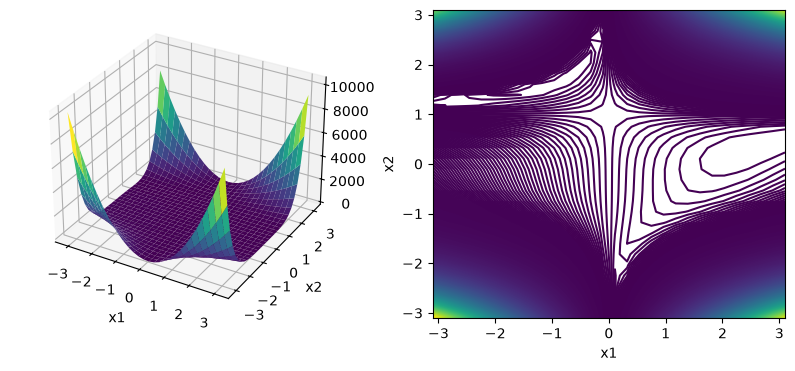

In [119]:
w = 3.1
N = 30
x = np.linspace(-w,w,N)
x1, x2 = np.meshgrid(x, x)
#x2 = np.array(x2).transpose(2,1,0)  # (x0,x1) in last dimention
y = Beale((x1, x2))
# two subplots, unpack the axes array immediately
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = fig.add_subplot(1, 2, 1, projection='3d')
ax.plot_surface(x1, x2, y, cmap='viridis')
axes[0].axis('off')
axes[1].contour(x1, x2, y, levels=10000, cmap='viridis')
ax.set_xlabel("x1"); ax.set_ylabel("x2");    
axes[1].set_xlabel("x1"); axes[1].set_ylabel("x2");    

3) Mixmize or minimize the function using two or more optimization algorithms, e.g.

* Gradient ascent/descent
* Newton-Raphson method
* Evolutionary algorithm
* scpy.optimize

and compare the results with different starting points and parameters.

In [44]:
def grad_descent(f, df, x0, eta=0.01, eps=1e-6, imax=1000):
    """Gradient descent"""
    xh = np.zeros((imax+1, len(np.ravel([x0]))))  # history
    xh[0] = x0
    f0 = f(x0)  # initialtization
    for i in range(imax):
        x1 = x0 - eta*df(x0)
        f1 = f(x1)
        # print(x1, f1)
        xh[i+1] = x1
        if(f1 <= f0 and f1 > f0 - eps):  # small decrease
            return(x1, f1, xh[:i+2])
        x0 = x1
        f0 = f1
    print("Failed to converge in ", imax, " iterations.")
    return(x1, f1, xh)

In [46]:
def himmelblau_grad(x):
    x = np.array(x)
    df_dx0 = 4*x[0]*(x[0]**2 + x[1]**2 - 11) + 2*(x[0] + x[1]**2 - 7)
    df_dx1 = 4*x[1]*(x[0] + x[1]**2 - 7) + 2*(x[0]**2 + x[1]**2 - 11)
    return np.array([df_dx0, df_dx1])

[2.56132317 2.10690568] 4.6767052301785e-07
[2.56138667 2.10677274] 6.660003721706828e-07
[-1.56154538 -2.92602651] 1.0386748027092062e-08
[-1.56156555  2.92599084] 2.8722314066898455e-08
[ 2.56162289 -2.10673046] 5.4735483513295843e-08


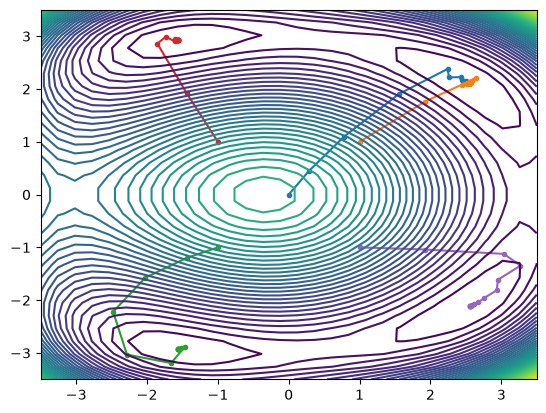

In [62]:
starting_points = [[0, 0], [1, 1], [-1, -1], [-1, 1], [1, -1]]
for x0 in starting_points:
    xmin, fmin, xhist = grad_descent(himmelblau, himmelblau_grad, x0, 0.02)
    print(xmin, fmin)
    plt.plot(xhist[:,0], xhist[:,1], '.-')
plt.contour(x1, x2, y, levels=50, cmap='viridis')

In [58]:
def evol_min(f, x0, sigma=0.1, imax=100):
    """simple evolutionary algorithm
    f: function to be minimized
    x0: initial population (p*n)
    sigma: mutation size"""
    p, n = x0.shape  # population, dimension
    x1 = np.zeros((p, n))
    xh = np.zeros((imax, n))  # history
    for i in range(imax):
        f0 = f(x0.T)  # evaluate the current population
        fmin = min(f0)
        xmin = x0[np.argmin(f0)]
        #print(xmin, fmin)
        xh[i] = xmin  # record the best one
        # roulette selection
        fitness = max(f0) - f0  # how much better than the worst
        prob = fitness/sum(fitness)  # selection probability
        #print(prob)
        for j in range(p):  # pick a parent for j-th baby
            parent = np.searchsorted(np.cumsum(prob), np.random.random())
            x1[j] = x0[parent] + sigma*np.random.randn(n)
        x0 = x1
    return(xmin, fmin, xh)

[2.85892675 1.76352958] 0.021859261700882315


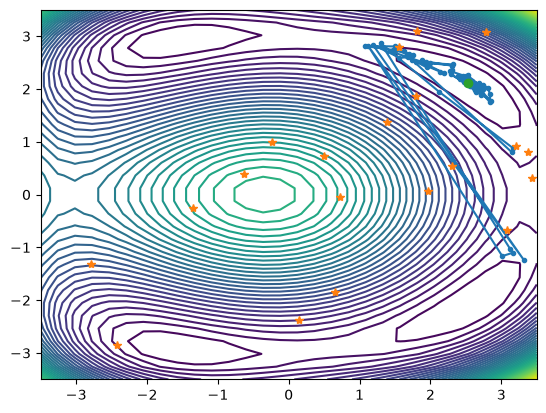

In [66]:
x0 = np.random.rand(20, 2)*7 - 3.5
xmin, fmin, xhist = evol_min(himmelblau, x0, 0.1)
print(xmin, fmin)
plt.contour(x1, x2, y, levels=50, cmap='viridis')
plt.plot(xhist[:,0], xhist[:,1], '.-')
plt.plot(x0[:,0], x0[:,1], '*')
plt.plot(xhist[-1,0], xhist[-1,1], 'o')

In [ ]:
from scipy.optimize import minimize

In [75]:
starting_points = [[0, 0], [1, 1], [-1, -1], [-1, 1], [1, -1]]
for x0 in starting_points:
    result = minimize(himmelblau, x0, options={'disp': True})
    print( result.x, result.fun)

Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 13
         Function evaluations: 168
         Gradient evaluations: 56
[2.56155294 2.10676217] 1.323430174582549e-13
Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 10
         Function evaluations: 48
         Gradient evaluations: 16
[2.56155281 2.10676225] 1.227017810047818e-15
Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 9
         Function evaluations: 45
         Gradient evaluations: 15
[-1.56155282 -2.92601313] 3.1257104073401377e-15
Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 9
         Function evaluations: 45
         Gradient evaluations: 15
[-1.56155284  2.92601311] 9.735922810079721e-15
Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 10
         Function ev

In [120]:
def Beale_grad(x):
    x = np.array(x)
    df_dx0 = 2*(1.5 - x[0] + x[0]*x[1])*(-1 + x[1]) + 2*(2.25 - x[0] + x[0]*x[1]**2)*(-1 + x[1]**2) + 2*(2.625 - x[0] + x[0]*x[1]**3)*(-1 + x[1]**3)
    df_dx1 = 2*(1.5 - x[0] + x[0]*x[1])*(x[0]) + 4.5*(2.25 - x[0] + x[0]*x[1]**2)*(x[0]*x[1]) + 7.875*(2.625 - x[0] + x[0]*x[1]**3)*(x[0]*x[1]**2)
    return np.array([df_dx0, df_dx1])

Locator attempting to generate 6947 ticks ([0.0, ..., 10419.0]), which exceeds Locator.MAXTICKS (1000).


[2.97422767 0.49327931] 0.00011093795317008481
[2.97426118 0.49328815] 0.00011064543075386676
[2.97420955 0.49327453] 0.00011109627461490422
[2.97423837 0.49328213] 0.00011084452614752084
[2.97427642 0.49329217] 0.00011051253797812693


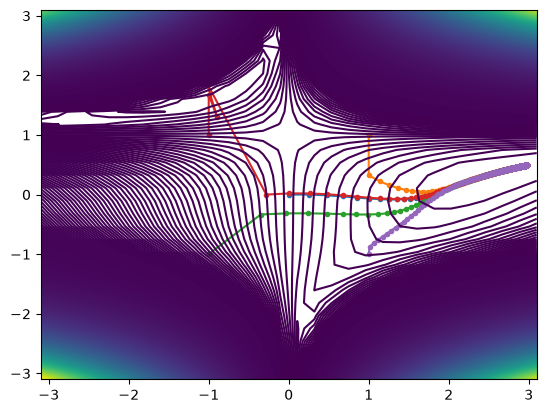

In [122]:
starting_points = [[0, 0], [1, 1], [-1, -1], [-1, 1], [1, -1]]
for x0 in starting_points:
    xmin, fmin, xhist = grad_descent(Beale, Beale_grad, x0, 0.02)
    print(xmin, fmin)
    plt.plot(xhist[:,0], xhist[:,1], '.-')
plt.contour(x1, x2, y, levels=10000, cmap='viridis')

In [123]:
starting_points = [[0, 0], [1, 1], [-1, -1], [-1, 1], [1, -1]]
for x0 in starting_points:
    result = minimize(Beale, x0, options={'disp': True})
    print( result.x, result.fun)

Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 13
         Function evaluations: 48
         Gradient evaluations: 16
[3.00000012 0.50000005] 9.027281496644589e-15
Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 15
         Function evaluations: 51
         Gradient evaluations: 17
[2.99999967 0.49999991] 1.991105451550448e-14
Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 14
         Function evaluations: 54
         Gradient evaluations: 18
[2.99998179 0.49999543] 5.3153796331676406e-11
         Current function value: 0.454363
         Iterations: 167
         Function evaluations: 784
         Gradient evaluations: 258
[-648.96511935    1.00152592] 0.4543632985525145
Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 14
         Function evaluations: 45
         Gradient eva

/Users/xiuningzhang/miniforge3/envs/sc_3.14.7/lib/python3.14/site-packages/scipy/optimize/_minimize.py:779: OptimizeWarning: Desired error not necessarily achieved due to precision loss.
  res = _minimize_bfgs(fun, x0, args, jac, callback, **options)


Option) Set equality or inequality constraints and apply an algorithm for constrained optimization.

In [77]:
def h(x):
    return -x[0] + 0.6*x[1] - 0.6
def h_grad(x):
    return np.array([-1, 0.6])

Iteration limit reached    (Exit mode 9)
            Current function value: 5.222908854910797
            Iterations: 100
            Function evaluations: 1048
            Gradient evaluations: 101
[-2.22453831 -2.70756385] 5.222908854910797


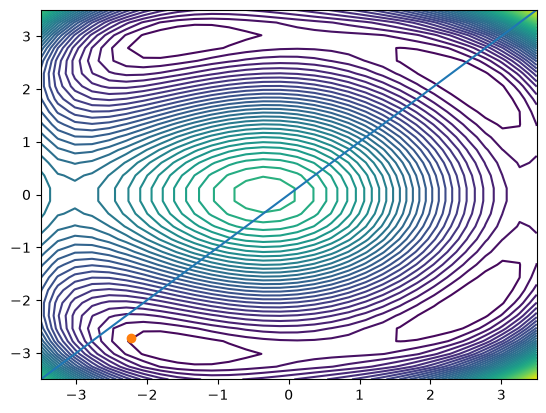

In [ ]:
cons = ({'type':'eq', 'fun':h, 'jac':h_grad})
result = minimize(himmelblau, [1,-3], jac=himmelblau_grad,
            method='SLSQP', constraints=cons, options={'disp': True})
print(result.x, result.fun)
plt.contour(x1, x2, y, levels=50, cmap='viridis')
plt.plot([-3.5,3.5], [-3.5,3.5])  # h(x) = 0
plt.plot(result.x[0], result.x[1], 'o')

In [143]:
def ellipse(x):
    return -(x[0]/3.5)**2 - (x[1]/2)**2 - 1

def ellipse_grad(x):
    x = np.array(x)
    df_dx0 = -2*(x[0]/3.5**2)
    df_dx1 = -2*(x[1]/2**2)
    return np.array([df_dx0, df_dx1])

Iteration limit reached    (Exit mode 9)
            Current function value: 169.999997432812
            Iterations: 100
            Function evaluations: 1017
            Gradient evaluations: 101
[ 1.83370523e-07 -9.91376027e-09] 169.999997432812


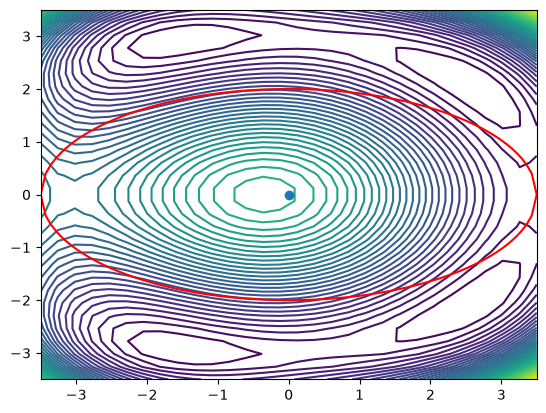

In [144]:
cons = ({'type':'ineq', 'fun':ellipse, 'jac':ellipse_grad})
result = minimize(himmelblau, [1,-3], jac=himmelblau_grad,
            method='SLSQP', constraints=cons, options={'disp': True})
print(result.x, result.fun)
plt.contour(x1, x2, y, levels=50, cmap='viridis')
plt.plot(result.x[0], result.x[1], 'o')
x = np.linspace(-3.5, 3.5, 100)
plt.plot(x, 2*np.sqrt(1-(x/3.5)**2), 'r')
plt.plot(x, -2*np.sqrt(1-(x/3.5)**2), 'r')